# FedSS 达到指定精度所需的通信轮次

读取当前目录中的 FedSS CSV 实验结果，找出每个文件首次达到指定测试精度的通信轮次，并按 FedSS 参数绘图。未达到目标精度的实验会保留在结果表中，并在图的顶部用红色叉号标出。

In [2]:
from pathlib import Path
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

TARGET_ACCURACY = 0.78  # 在这里修改目标精度
DATA_DIR = Path.cwd()

# 如果从仓库根目录运行 notebook，也能自动找到数据目录。
if not list(DATA_DIR.glob('fmnist_fedss_*.csv')):
    DATA_DIR = Path('close-optimal-result/f-mnist/dirichlet_0_4_10/epoch10')

print(f'数据目录: {DATA_DIR.resolve()}')
print(f'目标精度: {TARGET_ACCURACY:.2%}')

数据目录: D:\vscode\CODES\paper_experiment_record\close-optimal-result\f-mnist\dirichlet_0_4_10\epoch10
目标精度: 78.00%


In [3]:
def read_experiment_csv(csv_path):
    """自动定位 round,accuracy 表头并读取实验数据。"""
    header_row = None
    with csv_path.open('r', encoding='utf-8-sig') as f:
        for i, line in enumerate(f):
            columns = [item.strip() for item in line.strip().split(',')]
            if 'round' in columns and 'accuracy' in columns:
                header_row = i
                break

    if header_row is None:
        raise ValueError('未找到包含 round 和 accuracy 的表头')

    data = pd.read_csv(csv_path, skiprows=header_row)
    data['round'] = pd.to_numeric(data['round'], errors='coerce')
    data['accuracy'] = pd.to_numeric(data['accuracy'], errors='coerce')
    return data.dropna(subset=['round', 'accuracy']).sort_values('round')


def extract_fedss_parameter(filename):
    """例如 010 -> 0.10，100 -> 1.00；也兼容带时间戳的文件名。"""
    match = re.search(r'fmnist_fedss_(\d{2,3})(?:_epoch10)', filename)
    if match is None:
        return None
    token = match.group(1)
    return int(token) / (100 if len(token) == 3 else 10)


records = []
for csv_path in sorted(DATA_DIR.glob('*.csv')):
    parameter = extract_fedss_parameter(csv_path.name)
    if parameter is None:
        print(f'跳过无法识别 FedSS 参数的文件: {csv_path.name}')
        continue

    try:
        data = read_experiment_csv(csv_path)
        reached = data.loc[data['accuracy'] >= TARGET_ACCURACY]
        first_round = reached.iloc[0]['round'] if not reached.empty else np.nan
        first_accuracy = reached.iloc[0]['accuracy'] if not reached.empty else np.nan
        records.append({
            'fedss_parameter': parameter,
            'first_round': first_round,
            'accuracy_at_first_round': first_accuracy,
            'max_accuracy': data['accuracy'].max(),
            'reached_target': not reached.empty,
            'file': csv_path.name,
        })
    except Exception as exc:
        print(f'读取失败: {csv_path.name}: {exc}')

results = pd.DataFrame(records).sort_values(['fedss_parameter', 'file']).reset_index(drop=True)
results

,fedss_parameter,first_round,accuracy_at_first_round,max_accuracy,reached_target,file
0,0.10,260,0.7853,0.8016,True,fmnist_fedss_010_epoch10.csv
1,0.15,218,0.7809,0.8170,True,fmnist_fedss_015_epoch10.csv
2,0.20,248,0.7817,0.8111,True,fmnist_fedss_020_epoch10.csv
3,0.23,218,0.7879,0.8103,True,fmnist_fedss_023_epoch10.csv
4,0.27,237,0.7803,0.8114,True,fmnist_fedss_027_epoch10.csv
5,0.30,251,0.7810,0.8074,True,fmnist_fedss_030_epoch10.csv
6,0.32,218,0.7826,0.8154,True,fmnist_fedss_032_epoch10.csv
7,0.35,237,0.7808,0.8123,True,fmnist_fedss_035_epoch10.csv
8,0.38,230,0.7827,0.8140,True,fmnist_fedss_038_epoch10.csv
9,0.40,257,0.7828,0.8025,True,fmnist_fedss_040_epoch10.csv


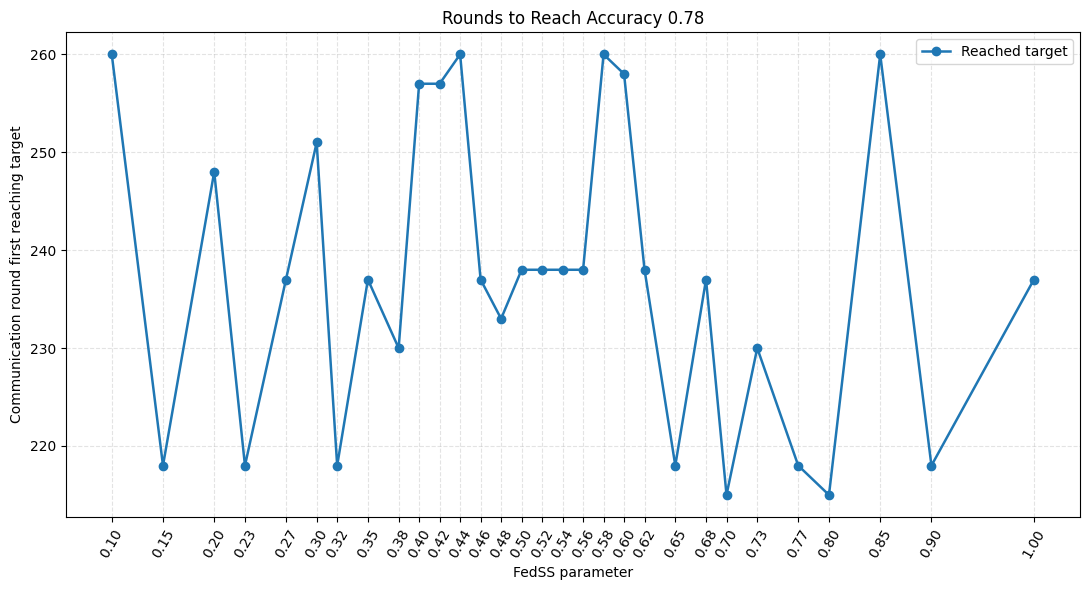

达到目标: 30/30 个文件


In [28]:
if results.empty:
    raise RuntimeError('没有找到可用的 FedSS CSV 文件。')

fig, ax = plt.subplots(figsize=(11, 6))
reached = results[results['reached_target']]
not_reached = results[~results['reached_target']]

ax.plot(
    reached['fedss_parameter'], reached['first_round'],
    marker='o', linewidth=1.8, markersize=6, label='Reached target'
)

# 未达到目标的参数没有真实的首次轮次，在图顶部单独标记。
if not not_reached.empty:
    observed_max_round = reached['first_round'].max() if not reached.empty else 0
    marker_y = max(observed_max_round + 10, 310)
    ax.scatter(
        not_reached['fedss_parameter'], [marker_y] * len(not_reached),
        color='crimson', marker='x', s=70, label='Target not reached'
    )

ax.set_xlabel('FedSS parameter')
ax.set_ylabel('Communication round first reaching target')
ax.set_title(f'Rounds to Reach Accuracy {TARGET_ACCURACY:.2f}')
ax.set_xticks(sorted(results['fedss_parameter'].unique()))
ax.tick_params(axis='x', rotation=60)
ax.grid(True, linestyle='--', alpha=0.35)
ax.legend()
fig.tight_layout()
plt.show()

print(f'达到目标: {results.reached_target.sum()}/{len(results)} 个文件')
if not not_reached.empty:
    print('未达到目标的参数:', not_reached['fedss_parameter'].tolist())

,fedss_parameter,first_round,three_round_avg_accuracy,reached_target,file
0,0.10,262,0.781900,True,fmnist_fedss_010_epoch10.csv
1,0.15,237,0.781467,True,fmnist_fedss_015_epoch10.csv
2,0.20,253,0.780167,True,fmnist_fedss_020_epoch10.csv
3,0.23,236,0.780667,True,fmnist_fedss_023_epoch10.csv
4,0.27,253,0.780600,True,fmnist_fedss_027_epoch10.csv
5,0.30,258,0.780267,True,fmnist_fedss_030_epoch10.csv
6,0.32,238,0.784833,True,fmnist_fedss_032_epoch10.csv
7,0.35,239,0.780967,True,fmnist_fedss_035_epoch10.csv
8,0.38,238,0.784167,True,fmnist_fedss_038_epoch10.csv
9,0.40,258,0.780433,True,fmnist_fedss_040_epoch10.csv


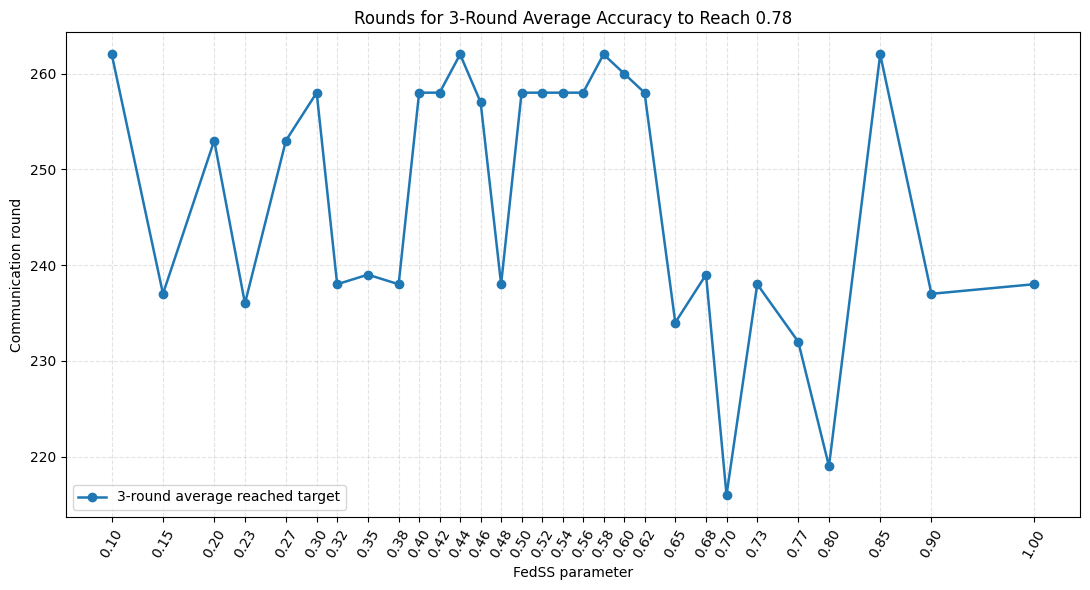

连续三轮平均精度达到目标: 30/30 个文件


In [4]:
# 连续三轮的平均精度首次达到 TARGET_ACCURACY 时所需的通信轮次
three_round_records = []

for csv_path in sorted(DATA_DIR.glob('*.csv')):
    parameter = extract_fedss_parameter(csv_path.name)
    if parameter is None:
        continue

    try:
        data = read_experiment_csv(csv_path).reset_index(drop=True)
        data['three_round_avg_accuracy'] = data['accuracy'].rolling(window=3).mean()

        # 同时确认窗口中的 round 确实是连续的三轮。
        round_diff = data['round'].diff()
        is_three_consecutive_rounds = round_diff.eq(1) & round_diff.shift(1).eq(1)
        reached = data.loc[
            is_three_consecutive_rounds
            & (data['three_round_avg_accuracy'] >= TARGET_ACCURACY)
        ]

        first_round = reached.iloc[0]['round'] if not reached.empty else np.nan
        first_avg_accuracy = (
            reached.iloc[0]['three_round_avg_accuracy'] if not reached.empty else np.nan
        )
        three_round_records.append({
            'fedss_parameter': parameter,
            'first_round': first_round,
            'three_round_avg_accuracy': first_avg_accuracy,
            'reached_target': not reached.empty,
            'file': csv_path.name,
        })
    except Exception as exc:
        print(f'读取失败: {csv_path.name}: {exc}')

three_round_results = (
    pd.DataFrame(three_round_records)
    .sort_values(['fedss_parameter', 'file'])
    .reset_index(drop=True)
)
display(three_round_results)

if three_round_results.empty:
    raise RuntimeError('没有找到可用的 FedSS CSV 文件。')

reached_three = three_round_results[three_round_results['reached_target']]
not_reached_three = three_round_results[~three_round_results['reached_target']]

fig, ax = plt.subplots(figsize=(11, 6))
ax.plot(
    reached_three['fedss_parameter'],
    reached_three['first_round'],
    marker='o', linewidth=1.8, markersize=6,
    label='3-round average reached target',
)

if not not_reached_three.empty:
    observed_max_round = (
        reached_three['first_round'].max() if not reached_three.empty else 0
    )
    marker_y = max(observed_max_round + 10, 310)
    ax.scatter(
        not_reached_three['fedss_parameter'],
        [marker_y] * len(not_reached_three),
        color='crimson', marker='x', s=70, label='Target not reached',
    )

ax.set_xlabel('FedSS parameter')
ax.set_ylabel('Communication round')
ax.set_title(
    f'Rounds for 3-Round Average Accuracy to Reach {TARGET_ACCURACY:.2f}'
)
ax.set_xticks(sorted(three_round_results['fedss_parameter'].unique()))
ax.tick_params(axis='x', rotation=60)
ax.grid(True, linestyle='--', alpha=0.35)
ax.legend()
fig.tight_layout()
plt.show()

print(
    f'连续三轮平均精度达到目标: '
    f'{three_round_results.reached_target.sum()}/{len(three_round_results)} 个文件'
)